# Labyrinth Level

Labyrinth Level turns a level design into a maze a game can load. Every room is a qubit. Neighbouring rooms the design wants open are set to agree, the rest to disagree; after sampling, rooms that agree are joined by a corridor and rooms that disagree get a wall. On hardware, noise reshapes the level, and that's part of the result.

## Setup

In [1]:
import getpass
import os
import json

import matplotlib.pyplot as plt

from moth_atlas import Atlas

ENGINE = "labyrinth-staging"  # the engine this notebook runs: Atlas V2 (staging). Production: "labyrinth-v1"

if not os.environ.get("MOTH_API_KEY"):
    os.environ["MOTH_API_KEY"] = getpass.getpass("Atlas API key")

client = Atlas()  # reads MOTH_API_KEY, and MOTH_API_BASE for which API to call

In [2]:
def load(path):
    with open(path) as f:
        return json.load(f)


def neighbours(rows, cols):
    """Every pair of side-by-side or stacked rooms on the grid."""
    pairs = [(r * cols + c, r * cols + c + 1) for r in range(rows) for c in range(cols - 1)]
    return pairs + [(r * cols + c, (r + 1) * cols + c) for r in range(rows - 1) for c in range(cols)]


def walls(level, view="measured", rank=0):
    """Which neighbouring rooms are split by a wall. Rooms with no coupling between them always are.
    view: "designed" (target sign −1), "measured" (ZZ came out negative) or "shot" (bits differ in one shot;
    rank 0 is the most frequent)."""
    g = level["grid_size"]
    wall = {pair: True for pair in neighbours(g["rows"], g["cols"])}
    if view == "designed":
        wall.update({tuple(sorted(e["qubits"])): e["sign"] < 0 for e in level["target"]["edge_signs"]})
    elif view == "measured":
        wall.update({tuple(sorted(c["qubits"])): c["value"] < 0 for c in level["results"]["zz_couplings"]})
    else:
        bits = level["results"]["measurements"][rank]["bitstring"]
        wall.update({tuple(sorted(c["qubits"])): bits[c["qubits"][0]] != bits[c["qubits"][1]]
                     for c in level["results"]["zz_couplings"]})
    return wall


def mazes(level, views, size=2.6):
    """Draw {label: walls} for one level, side by side: rooms are cells, walls thick lines, radiating rooms marked."""
    rows, cols = level["grid_size"]["rows"], level["grid_size"]["cols"]
    radiating = [int(q) for q, s in level.get("initial_states", {}).items() if s.get("radiating")]
    fig, axes = plt.subplots(1, len(views), figsize=(size * len(views) * cols / max(rows, cols) + 0.3, size), squeeze=False)
    for ax, (label, wall) in zip(axes[0], views.items()):
        ax.add_patch(plt.Rectangle((0, 0), cols, rows, fill=False, lw=3))
        for (a, b), is_wall in wall.items():
            if not is_wall:
                continue
            (ra, ca), (rb, cb) = divmod(a, cols), divmod(b, cols)
            if ra == rb:  # side by side: a vertical wall between them
                ax.plot([max(ca, cb)] * 2, [rows - ra - 1, rows - ra], "k", lw=3)
            else:         # one above the other: a horizontal wall
                ax.plot([ca, ca + 1], [rows - max(ra, rb)] * 2, "k", lw=3)
        for q in radiating:
            r, c = divmod(q, cols)
            ax.plot(c + 0.5, rows - r - 0.5, "o", color="C1", ms=8)
        ax.set_xlim(-0.1, cols + 0.1)
        ax.set_ylim(-0.1, rows + 0.1)
        ax.set_aspect("equal")
        ax.set_axis_off()
        ax.set_title(label, fontsize=9)
    plt.show()


def compare(level):
    """How the measured walls match the design, over the coupled edges."""
    d, m = walls(level, "designed"), walls(level, "measured")
    coupled = [tuple(sorted(e["qubits"])) for e in level["target"]["edge_signs"]]
    closed = sum(m[e] and not d[e] for e in coupled)
    opened = sum(d[e] and not m[e] for e in coupled)
    return f"{sum(d[e] == m[e] for e in coupled)}/{len(coupled)} edges as designed, {closed} corridors closed, {opened} walls opened"

## Try it

`easy.json` beside this notebook is the Easy level from Atlas's Labyrinth demo: 4 × 5 rooms (20 qubits), each starting pointed up or down, which is what sets the design. Rooms with no coupling between them are always walled. The run takes about 15 seconds on the emulator.

labyrinth-staging job b81b4d04 submitted
labyrinth-staging job b81b4d04 completed (14s)


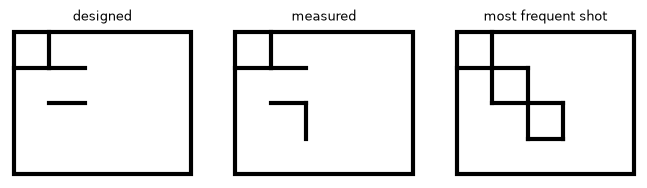

30/31 edges as designed, 1 corridors closed, 0 walls opened


In [3]:
job = client.jobs.run(
    engine=ENGINE,
    params={
        "level_data": load("easy.json"),
        "shots": 4096,
        "steps": 3,
        "mode": "emu",
    },
)
out = job.result["output"]
mazes(out, {"designed": walls(out, "designed"), "measured": walls(out, "measured"), "most frequent shot": walls(out, "shot")})
print(compare(out))

## Parameters

What to expect from each:

- `level_data`: the level: `grid_size`, `num_qubits` (rows × cols), `coupling_map` (which neighbouring rooms can open onto each other), `initial_states` (each room's starting Bloch vector, which sets the design, and game flags such as `radiating`, carried through to the output) and `relationships`.
- `shots` (up to 10,000): how many times the level is measured. More shots, steadier walls.
- `steps` (1 to 5): how many sweeps build up the correlations before measuring.
- `fraction`: how strongly each sweep ties neighbours together, as a fraction of a full rotation (default 1/3).
- `k` (1 to 4): how many connected rooms each tracked correlation spans. Higher is more faithful and slower.
- `top_n`: how many of the most frequent shots the output keeps (−1 keeps all).
- `mode`: `emu` simulates (up to 20 rooms); `qpu` runs on IBM hardware (your account needs access).

It returns the level with `target` (the designed edge signs), `results` (`measurements`, `z_expectations`, `zz_couplings`) and `metrics`.

In [4]:
# client.engines.get(ENGINE)  # its description, params, input and output files, from the API

## How it works

**Design to targets.** Each coupled pair of rooms gets a target sign from their starting states: $+1$ (a corridor) where they point the same way, $-1$ (a wall) where they point opposite ways. Uncoupled neighbours are walls whatever happens.

**Prepare.** `steps` sweeps of $ZZ$ rotations (each a `fraction` of a full turn) pull every coupled pair towards its target correlation, on one quantum graph state spanning all rooms. Tomography over paths of `k` rooms tracks how the state is doing.

**Read the maze.** The state is measured `shots` times. Two maze readings come out: the measured correlation of each edge ($\langle Z_aZ_b\rangle < 0$ is a wall), and each individual shot, where neighbouring bits that differ are a wall. No two shots need be the same maze.

**Noise.** On hardware, noise weakens correlations: a designed wall can vanish, a corridor close. The saved IBM Miami run at the end shows a whole 6 × 6 level shaped that way.

## Experiments

Each experiment changes one parameter and keeps the others fixed, and runs one job per value.

### Difficulty

Atlas's four levels: harder ones couple fewer rooms (more fixed walls) and start more rooms sideways (0 instead of ±1), so their correlations are weaker and the measured maze strays further from the design. Orange dots are radiating rooms.

easy
  30/31 edges as designed, 1 corridors closed, 0 walls opened


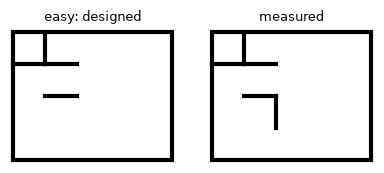

medium
  30/31 edges as designed, 1 corridors closed, 0 walls opened


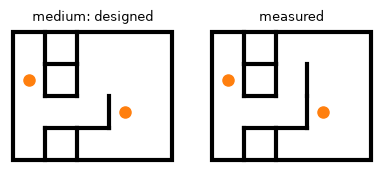

hard
  29/31 edges as designed, 2 corridors closed, 0 walls opened


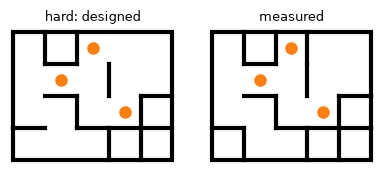

nightmare
  31/31 edges as designed, 0 corridors closed, 0 walls opened


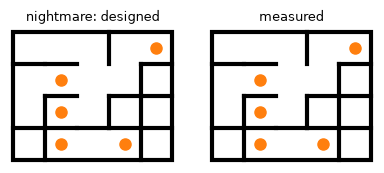

In [5]:
for name in ("easy", "medium", "hard", "nightmare"):
    print(name)
    out = client.jobs.run(engine=ENGINE, params={"level_data": load(f"{name}.json")}, quiet=True).result["output"]
    print(" ", compare(out))
    mazes(out, {f"{name}: designed": walls(out, "designed"), "measured": walls(out, "measured")}, size=2.2)

### Shots

With few shots, measured correlations are noisy and walls flicker; with more they settle.

shots=128
  29/31 edges as designed, 0 corridors closed, 2 walls opened
shots=1024
  29/31 edges as designed, 0 corridors closed, 2 walls opened
shots=8192
  31/31 edges as designed, 0 corridors closed, 0 walls opened


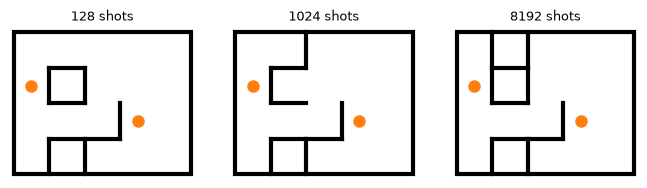

In [6]:
level, views = load("medium.json"), {}
for shots in (128, 1024, 8192):
    print(f"shots={shots}")
    out = client.jobs.run(engine=ENGINE, params={"level_data": level, "shots": shots}, quiet=True).result["output"]
    views[f"{shots} shots"] = walls(out, "measured")
    print(" ", compare(out))
mazes(out, views)

### Steps

More sweeps build stronger correlations, so the measured maze moves closer to the design.

steps=1
  31/31 edges as designed, 0 corridors closed, 0 walls opened
steps=2
  31/31 edges as designed, 0 corridors closed, 0 walls opened
steps=3
  30/31 edges as designed, 0 corridors closed, 1 walls opened
steps=5
  28/31 edges as designed, 1 corridors closed, 2 walls opened


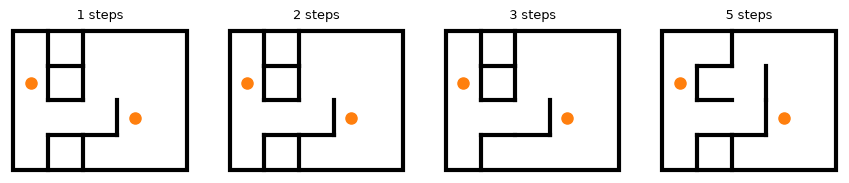

In [7]:
views = {}
for steps in (1, 2, 3, 5):
    print(f"steps={steps}")
    out = client.jobs.run(engine=ENGINE, params={"level_data": level, "steps": steps}, quiet=True).result["output"]
    views[f"{steps} steps"] = walls(out, "measured")
    print(" ", compare(out))
mazes(out, views)

### Shots as mazes

Every shot is a maze of its own. The five most frequent shots of one run:

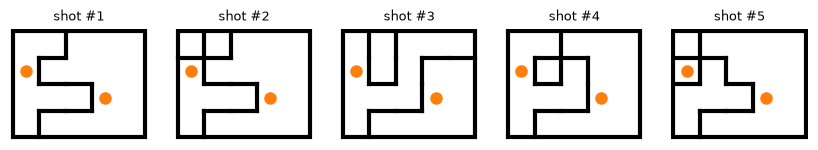

In [8]:
out = client.jobs.run(engine=ENGINE, params={"level_data": level, "shots": 4096}, quiet=True).result["output"]
top = min(5, len(out["results"]["measurements"]))
mazes(out, {f"shot #{rank + 1}": walls(out, "shot", rank) for rank in range(top)}, size=2.0)

### A full level on hardware

`level_2_final_miami.json` is a 6 × 6 Backrooms Labyrinth level (36 rooms) with the result of a run on IBM's Miami chip saved in it. 36 qubits is beyond the emulator, so this draws the saved run without a new job.

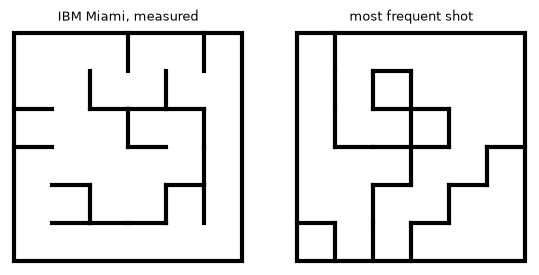

{'num_shots': 4096, 'steps': 2, 'fraction': 0.3333333333333333, 'depth_2q': 22}


In [9]:
miami = load("level_2_final_miami.json")
mazes(miami, {"IBM Miami, measured": walls(miami, "measured"), "most frequent shot": walls(miami, "shot")}, size=3.2)
print({k: miami["metrics"][k] for k in ("num_shots", "steps", "fraction", "depth_2q")})

## Questions

**How does a game load this?**

The output is the level JSON with `results` filled in: a game reads `zz_couplings` (or one bitstring from `measurements`) for the walls, and each room's flags from `initial_states`.

**Why do the designed and measured mazes differ on a simulator?**

Correlations are built up in `steps` sweeps of finite strength and estimated from finite shots, and neighbouring targets pull against each other. Rooms that start sideways have no preferred direction, so their edges are the least settled.

**How big can a level be?**

20 rooms (qubits) on the emulator. Larger levels need `mode: "qpu"` and QPU access.

**What's the Backrooms Labyrinth?**

Moth's quantum maze game, whose levels were measured on IBM hardware; the Miami level is one of them.